# TuneTwin AI - Testing Prototype

A student-readable, single-notebook prototype for music features, simulated feedback, regularized/tuned classifiers, ensembles, shared LinUCB, and optional Spotify playback. **ML TEST MODE works without Spotify credentials.** Dataset columns and Spotify availability are inspected rather than assumed.

This notebook mirrors the Flask app: the same derived features, PCA/K-Means representation, tuned classifier, and shared contextual bandit are used for live recommendations.


## 1. Project Setup
**What / why:** Load the analysis libraries, fix random seeds, and define paths and adjustable experiment settings. This keeps repeated notebook runs comparable.

In [1]:
from pathlib import Path
import os, re, warnings, json, ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score, accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, ndcg_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc,
)
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.metrics.pairwise import cosine_similarity
import joblib

SEED = 42
rng = np.random.default_rng(SEED)
DATA_PATH = Path("data/data.csv")  # Kaggle reference notebook uses data.csv; change as needed
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)
PCA_VARIANCE_TARGET = 0.90
HYBRID_CONTENT_WEIGHT = 0.75
HYBRID_SUPERVISED_WEIGHT = 0.25
CLASSIFIER_BLEND = 0.25
N_SIMULATED_USERS = 5
N_INTERACTIONS_PER_USER = 400
N_EPISODES = 200
LINUCB_ALPHA = 0.20
LINUCB_BLEND = 0.25
MIN_CLASSIFIER_EVENTS = 2
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Inconsistent values: penalty.*")
print("Setup complete. Seed:", SEED, "| Dataset path:", DATA_PATH.resolve())

Setup complete. Seed: 42 | Dataset path: C:\Users\Asmit\Documents\ml_project\data\data.csv


## 2. Dataset Loading
**What / why:** Read the selected CSV. If it is missing, show CSV files under `data/` and stop with an actionable message; no replacement or fabricated data is silently substituted.

In [2]:
# Honor the explicit path first. If it is absent, inspect CSV headers in data/ and select
# a track-level table with the most recognizable audio columns (grouped summary tables score lower).
audio_tokens = ("danceability", "energy", "acousticness", "instrumentalness", "liveness", "loudness", "speechiness", "valence", "tempo", "duration")
if not DATA_PATH.exists():
    csv_paths = list(Path("data").glob("*.csv")) if Path("data").exists() else []
    inspected = []
    for candidate in csv_paths:
        try:
            header = pd.read_csv(candidate, nrows=0).columns.tolist()
            audio_count = sum(any(token in str(c).lower() for token in audio_tokens) for c in header)
            inspected.append((audio_count, candidate, header))
        except Exception as exc:
            print(f"Could not inspect {candidate}: {exc}")
    qualified = [item for item in inspected if item[0] >= 2]
    if qualified:
        qualified.sort(key=lambda item: (item[0], item[1].name.lower() == "data.csv"), reverse=True)
        DATA_PATH = qualified[0][1]
        print("CSV header inspection:", [(str(p), score, cols[:12]) for score, p, cols in inspected])
    else:
        raise FileNotFoundError(
            f"No track-level CSV found. Download the CSV used by the Kaggle reference notebook, "
            f"place it at {Path('data/data.csv').resolve()} (or update DATA_PATH), and rerun. "
            f"CSV files inspected: {[str(p) for p in csv_paths]}"
        )
tracks_raw = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Loaded {len(tracks_raw):,} rows × {tracks_raw.shape[1]} columns from {DATA_PATH}")

Loaded 170,653 rows × 19 columns from data\data.csv


## 3. Dataset Inspection
**What / why:** Inspect the actual schema and identify likely metadata and numerical audio features. We do not invent absent columns.

In [3]:
print("Shape:", tracks_raw.shape)
display(pd.DataFrame({"dtype": tracks_raw.dtypes.astype(str), "missing": tracks_raw.isna().sum(), "unique": tracks_raw.nunique(dropna=True)}))
print("Exact duplicate rows:", int(tracks_raw.duplicated().sum()))
display(tracks_raw.head())
print("Columns:", tracks_raw.columns.tolist())

Shape: (170653, 19)


,dtype,missing,unique
valence,float64,0,1733
year,int64,0,100
acousticness,float64,0,4689
artists,object,0,34088
danceability,float64,0,1240
duration_ms,int64,0,51755
energy,float64,0,2332
explicit,int64,0,2
id,object,0,170653
instrumentalness,float64,0,5401


Exact duplicate rows: 0


,valence,year,acousticness,artists,danceability,duration_ms,energy,explicit,id,instrumentalness,key,liveness,loudness,mode,name,popularity,release_date,speechiness,tempo
0,0.0594,1921,0.982,"['Sergei Rachmaninoff', 'James Levine', 'Berli...",0.279,831667,0.211,0,4BJqT0PrAfrxzMOxytFOIz,0.878000,10,0.665,-20.096,1,"Piano Concerto No. 3 in D Minor, Op. 30: III. ...",4,1921,0.0366,80.954
1,0.9630,1921,0.732,['Dennis Day'],0.819,180533,0.341,0,7xPhfUan2yNtyFG0cUWkt8,0.000000,7,0.160,-12.441,1,Clancy Lowered the Boom,5,1921,0.4150,60.936
2,0.0394,1921,0.961,['KHP Kridhamardawa Karaton Ngayogyakarta Hadi...,0.328,500062,0.166,0,1o6I8BglA6ylDMrIELygv1,0.913000,3,0.101,-14.850,1,Gati Bali,5,1921,0.0339,110.339
3,0.1650,1921,0.967,['Frank Parker'],0.275,210000,0.309,0,3ftBPsC5vPBKxYSee08FDH,0.000028,5,0.381,-9.316,1,Danny Boy,3,1921,0.0354,100.109
4,0.2530,1921,0.957,['Phil Regan'],0.418,166693,0.193,0,4d6HGyGT8e121BsdKmw9v6,0.000002,3,0.229,-10.096,1,When Irish Eyes Are Smiling,2,1921,0.0380,101.665


Columns: ['valence', 'year', 'acousticness', 'artists', 'danceability', 'duration_ms', 'energy', 'explicit', 'id', 'instrumentalness', 'key', 'liveness', 'loudness', 'mode', 'name', 'popularity', 'release_date', 'speechiness', 'tempo']


## 4. EDA
**What / why:** Summarize numeric distributions, available genre and popularity fields, and correlations. These charts describe this CSV only.

Tracks: 170653 | columns: 19 | numeric columns: 15


,count,mean,std,min,25%,50%,75%,max
valence,170653.0,0.528587,0.263171,0.0,0.3170,0.540000,0.7470,1.000
year,170653.0,1976.787241,25.917853,1921.0,1956.0000,1977.000000,1999.0000,2020.000
acousticness,170653.0,0.502115,0.376032,0.0,0.1020,0.516000,0.8930,0.996
danceability,170653.0,0.537396,0.176138,0.0,0.4150,0.548000,0.6680,0.988
duration_ms,170653.0,230948.310666,126118.414668,5108.0,169827.0000,207467.000000,262400.0000,5403500.000
energy,170653.0,0.482389,0.267646,0.0,0.2550,0.471000,0.7030,1.000
explicit,170653.0,0.084575,0.278249,0.0,0.0000,0.000000,0.0000,1.000
instrumentalness,170653.0,0.167010,0.313475,0.0,0.0000,0.000216,0.1020,1.000
key,170653.0,5.199844,3.515094,0.0,2.0000,5.000000,8.0000,11.000
liveness,170653.0,0.205839,0.174805,0.0,0.0988,0.136000,0.2610,1.000


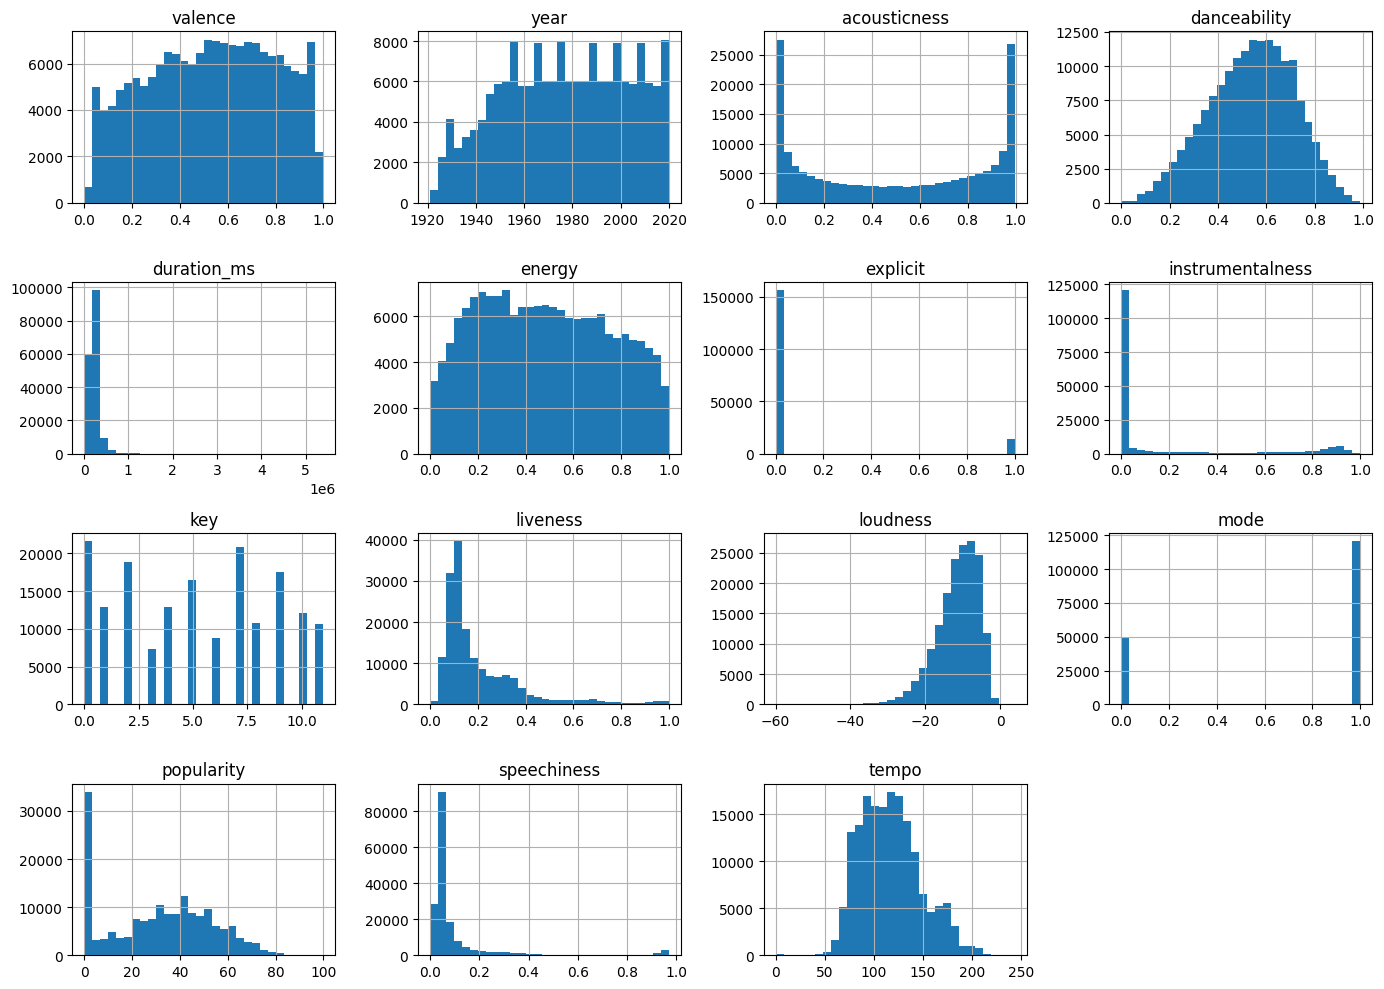

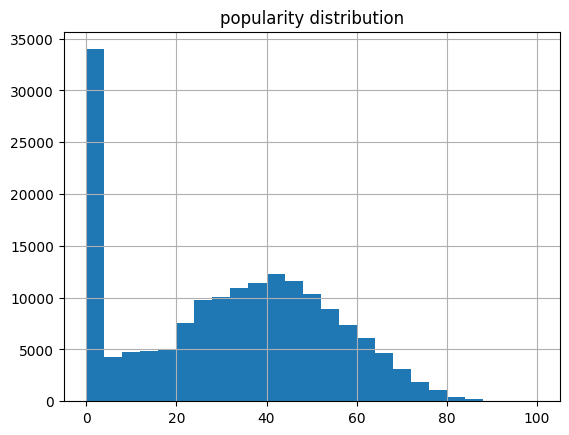

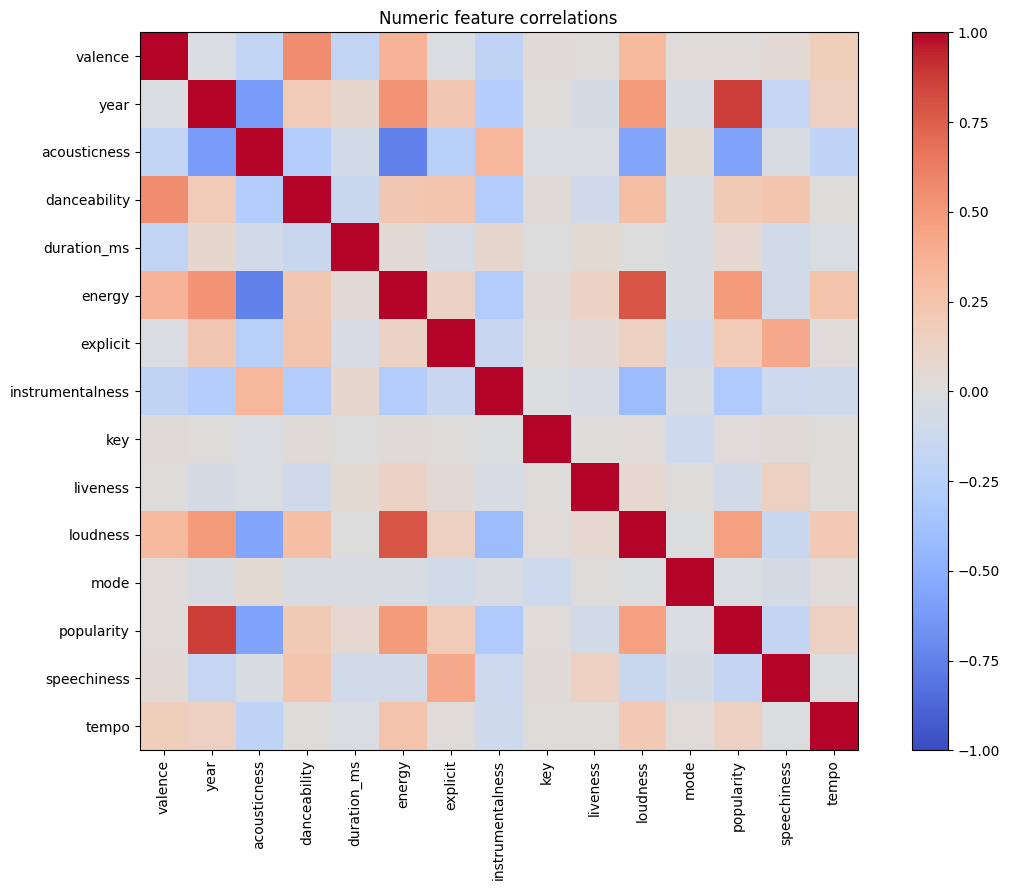

In [4]:
numeric_raw = tracks_raw.select_dtypes(include=np.number)
print("Tracks:", len(tracks_raw), "| columns:", tracks_raw.shape[1], "| numeric columns:", len(numeric_raw.columns))
display(numeric_raw.describe().T)
if len(numeric_raw.columns):
    numeric_raw.hist(figsize=(14, 10), bins=30); plt.tight_layout(); plt.show()
lower_cols = {str(c).lower(): c for c in tracks_raw.columns}
pop_col = next((lower_cols[k] for k in ["popularity"] if k in lower_cols), None)
genre_col = next((c for c in tracks_raw.columns if "genre" in str(c).lower()), None)
if pop_col:
    tracks_raw[pop_col].dropna().hist(bins=25); plt.title(f"{pop_col} distribution"); plt.show()
if genre_col:
    display(tracks_raw[genre_col].value_counts().head(20).rename("tracks").to_frame())
if len(numeric_raw.columns) > 1:
    corr = numeric_raw.corr()
    plt.figure(figsize=(12, 9)); plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1); plt.colorbar(); plt.xticks(range(len(corr)), corr.columns, rotation=90); plt.yticks(range(len(corr)), corr.columns); plt.title("Numeric feature correlations"); plt.tight_layout(); plt.show()

## 5. Data Preprocessing
**What / why:** Remove exact duplicate rows, coerce potential audio features to numeric, and keep descriptive metadata separate. A missing expected field simply stays unavailable.

In [5]:
tracks = tracks_raw.drop_duplicates().copy().reset_index(drop=True)
track_id_col = next((c for c in tracks.columns if str(c).strip().lower() in {"id", "track_id", "spotify_id"}), None)
if track_id_col:
    has_id = tracks[track_id_col].notna()
    duplicate_id_count = int(tracks.loc[has_id, track_id_col].duplicated().sum())
    tracks = pd.concat([tracks.loc[has_id].drop_duplicates(subset=[track_id_col], keep="first"), tracks.loc[~has_id]], ignore_index=True)
    print(f"Removed {duplicate_id_count} repeated track identifiers using {track_id_col!r}")
else:
    print("No recognized track identifier column; exact duplicate rows were removed only.")
metadata_tokens = ("id", "name", "artist", "album", "genre", "uri", "url", "type", "key", "mode")
preferred_tokens = ("danceability", "energy", "acousticness", "instrumentalness", "liveness", "loudness", "speechiness", "valence", "tempo", "duration")
feature_candidates = [c for c in tracks.columns if any(t in str(c).lower() for t in preferred_tokens)]
feature_candidates = [c for c in feature_candidates if not any(t in str(c).lower() for t in ("id", "name", "artist", "album", "genre"))]
for c in feature_candidates:
    tracks[c] = pd.to_numeric(tracks[c], errors="coerce")
feature_candidates = [c for c in feature_candidates if tracks[c].notna().sum() > 1 and tracks[c].nunique(dropna=True) > 1]
if len(feature_candidates) < 2:
    raise ValueError(f"Need at least 2 usable numeric audio feature columns; found {feature_candidates}. Inspect columns and update feature_candidates.")
metadata_cols = [c for c in tracks.columns if c not in feature_candidates]
metadata = tracks[metadata_cols].copy()
print("Candidate audio features actually found:", feature_candidates)
print("Metadata columns:", metadata_cols)
print("Rows after exact-duplicate removal:", len(tracks))

Removed 0 repeated track identifiers using 'id'
Candidate audio features actually found: ['valence', 'acousticness', 'danceability', 'duration_ms', 'energy', 'instrumentalness', 'liveness', 'loudness', 'speechiness', 'tempo']
Metadata columns: ['year', 'artists', 'explicit', 'id', 'key', 'mode', 'name', 'popularity', 'release_date']
Rows after exact-duplicate removal: 170653


## 6. Feature Engineering
**What / why:** Use only audio-like numeric columns present in the file. Drop columns with no numeric data, impute remaining missing values by median, cap extreme tails using training-independent 1st/99th percentiles, then standardize. Identifiers never enter the model.

In [6]:
BASE_FEATURES = list(feature_candidates)
feature_frame = tracks[BASE_FEATURES].replace([np.inf, -np.inf], np.nan)
feature_frame = feature_frame.apply(pd.to_numeric, errors="coerce")
usable = feature_frame.notna().sum() >= 2
feature_frame = feature_frame.loc[:, usable]
BASE_FEATURES = feature_frame.columns.tolist()
if len(BASE_FEATURES) < 2:
    raise ValueError("Fewer than two usable features remain after invalid-value cleaning.")

# Clip extreme tails before imputation. These bounds are stored in the shared
# artifact so the Flask app applies exactly the same preprocessing.
clip_lower = feature_frame.quantile(0.01)
clip_upper = feature_frame.quantile(0.99)
feature_frame = feature_frame.clip(lower=clip_lower, upper=clip_upper, axis="columns")
imputer = SimpleImputer(strategy="median")
base_imputed = pd.DataFrame(
    imputer.fit_transform(feature_frame), columns=BASE_FEATURES, index=tracks.index
)

def add_derived_features(frame):
    """Interaction features that describe how audio properties combine."""
    out = frame.copy()
    if {"energy", "valence"}.issubset(out.columns):
        out["energy_valence"] = out["energy"] * out["valence"]
    if {"danceability", "energy"}.issubset(out.columns):
        out["dance_energy"] = out["danceability"] * out["energy"]
    if {"acousticness", "instrumentalness"}.issubset(out.columns):
        out["acoustic_instrumental"] = out["acousticness"] * out["instrumentalness"]
    if "tempo" in out.columns:
        out["tempo_deviation"] = (out["tempo"] - out["tempo"].median()).abs()
    if "duration_ms" in out.columns:
        out["log_duration"] = np.log1p(out["duration_ms"].clip(lower=0))
    return out

X_imputed_df = add_derived_features(base_imputed)
FEATURES = X_imputed_df.columns.tolist()
DERIVED_FEATURES = [c for c in FEATURES if c not in BASE_FEATURES]
X_imputed = X_imputed_df.to_numpy(dtype=float)
feature_min = X_imputed_df.min().to_numpy(dtype=float)
feature_max = X_imputed_df.max().to_numpy(dtype=float)

# A common 0..1 space is used for simulated listener profiles and for the live
# profile derived from Like/Skip feedback in the app.
X_unit = np.clip(
    (X_imputed - feature_min) / np.where(feature_max > feature_min, feature_max - feature_min, 1),
    0, 1,
)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("Base features:", BASE_FEATURES)
print("Derived features:", DERIVED_FEATURES)
print("Final feature list:", FEATURES, "| matrix:", X_scaled.shape)
print("Rows with any originally missing feature:", int(feature_frame.isna().any(axis=1).sum()))

Base features: ['valence', 'acousticness', 'danceability', 'duration_ms', 'energy', 'instrumentalness', 'liveness', 'loudness', 'speechiness', 'tempo']
Derived features: ['energy_valence', 'dance_energy', 'acoustic_instrumental', 'tempo_deviation', 'log_duration']
Final feature list: ['valence', 'acousticness', 'danceability', 'duration_ms', 'energy', 'instrumentalness', 'liveness', 'loudness', 'speechiness', 'tempo', 'energy_valence', 'dance_energy', 'acoustic_instrumental', 'tempo_deviation', 'log_duration'] | matrix: (170653, 15)
Rows with any originally missing feature: 0


## 7. PCA
**What / why:** PCA rotates the standardized feature space into components that retain as much variance as possible. We select the component count that reaches the configured cumulative variance target and also make a 2D view where possible.

,component,explained_variance,cumulative
0,1,0.334441,0.334441
1,2,0.147674,0.482114
2,3,0.104461,0.586576
3,4,0.098672,0.685248
4,5,0.073296,0.758544
5,6,0.068577,0.827120
6,7,0.054134,0.881255
7,8,0.040504,0.921759
8,9,0.027881,0.949640
9,10,0.024191,0.973831


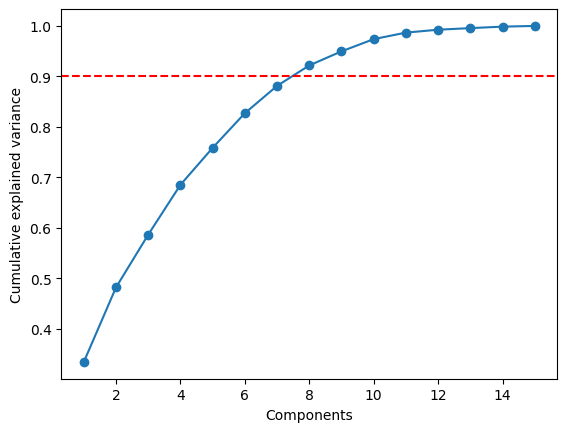

Selected 8 components; retained variance=0.922


In [7]:
pca_full = PCA(random_state=SEED).fit(X_scaled)
cumulative = np.cumsum(pca_full.explained_variance_ratio_)
n_components = int(np.searchsorted(cumulative, PCA_VARIANCE_TARGET) + 1)
pca = PCA(n_components=n_components, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
pca_2d = PCA(n_components=2, random_state=SEED).fit_transform(X_scaled)
display(pd.DataFrame({"component": np.arange(1, len(cumulative)+1), "explained_variance": pca_full.explained_variance_ratio_, "cumulative": cumulative}))
plt.plot(np.arange(1, len(cumulative)+1), cumulative, marker="o"); plt.axhline(PCA_VARIANCE_TARGET, color="red", linestyle="--"); plt.xlabel("Components"); plt.ylabel("Cumulative explained variance"); plt.show()
print(f"Selected {n_components} components; retained variance={pca.explained_variance_ratio_.sum():.3f}")

## 8. K-Means Clustering
**What / why:** Compare K values using inertia and silhouette score on a bounded sample for speed. Select the tested K with the highest measured silhouette; cluster labels are numeric and have no assumed mood meaning.

,k,inertia,silhouette
0,2,30669.391384,0.240474
1,3,26302.280884,0.231212
2,4,23671.221315,0.239491
3,5,21515.073530,0.234571
4,6,19730.125161,0.222097
5,7,18391.277738,0.208231
6,8,17326.489404,0.188208
7,9,16371.587510,0.191771
8,10,15621.513897,0.191895


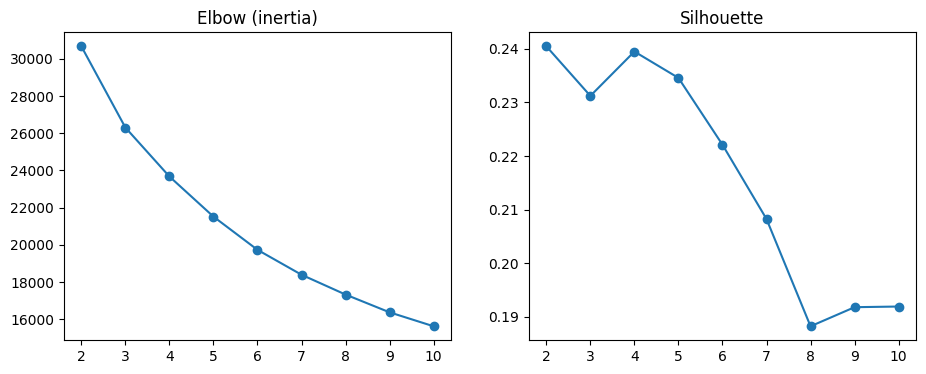

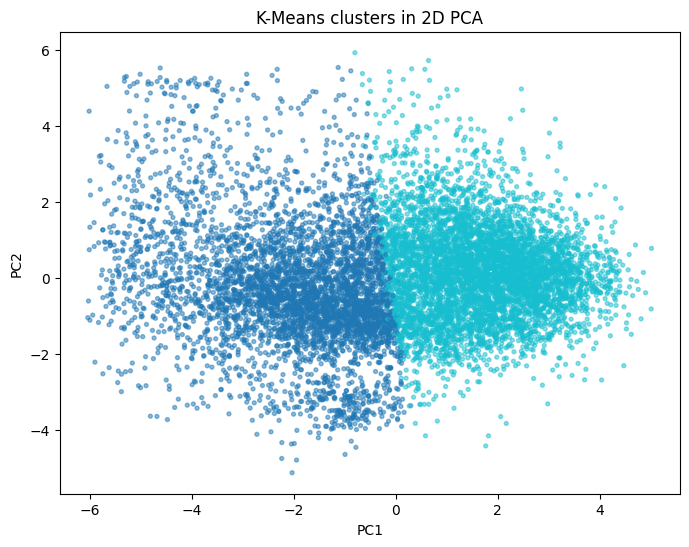

Tested K: [2, 3, 4, 5, 6, 7, 8, 9, 10] | selected: 2 | measured silhouette: 0.2404743257148331


In [8]:
n_rows = len(X_pca)
if n_rows < 3: raise ValueError("Need at least 3 usable tracks for clustering.")
cluster_space = X_pca if X_pca.shape[1] <= 15 else X_pca[:, :15]
max_k = min(10, n_rows - 1)
K_VALUES = list(range(2, max_k + 1))
cluster_sample_idx = rng.choice(n_rows, min(n_rows, 3000), replace=False)
sample_cluster_space = cluster_space[cluster_sample_idx]
cluster_rows = []
for k in K_VALUES:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(sample_cluster_space)
    sil = silhouette_score(sample_cluster_space, km.labels_) if len(cluster_sample_idx) > k else np.nan
    cluster_rows.append({"k": k, "inertia": km.inertia_, "silhouette": sil})
cluster_results = pd.DataFrame(cluster_rows)
display(cluster_results)
fig, ax = plt.subplots(1,2, figsize=(11,4)); ax[0].plot(cluster_results.k, cluster_results.inertia, marker="o"); ax[0].set_title("Elbow (inertia)"); ax[1].plot(cluster_results.k, cluster_results.silhouette, marker="o"); ax[1].set_title("Silhouette"); plt.show()
selected_k = int(cluster_results.loc[cluster_results.silhouette.idxmax(), "k"])
kmeans = KMeans(n_clusters=selected_k, random_state=SEED, n_init=10).fit(cluster_space)
cluster_labels = kmeans.labels_
plot_idx = rng.choice(n_rows, min(n_rows, 10000), replace=False)
plt.figure(figsize=(8,6)); plt.scatter(pca_2d[plot_idx,0], pca_2d[plot_idx,1], c=cluster_labels[plot_idx], s=8, alpha=.5, cmap="tab10"); plt.title("K-Means clusters in 2D PCA"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()
print("Tested K:", K_VALUES, "| selected:", selected_k, "| measured silhouette:", float(cluster_results.loc[cluster_results.k==selected_k, "silhouette"].iloc[0]))

## 9. Simulated User Profiles
**What / why:** Construct several preference vectors from empirical feature quantiles, so varied feature scales and dataset schema are respected. Profiles drive probabilistic feedback only; they do not directly assign recommendations.

In [9]:
# Preference targets only shape probabilistic simulated feedback; recommenders learn/rank separately.
profile_specs = [
    {"energy": .85, "danceability": .85},
    {"acousticness": .85, "energy": .20},
    {"instrumentalness": .95},
    {"valence": .90},
    {"energy": .65, "valence": .70, "danceability": .60, "acousticness": .45},
]
preference_profiles = {}
median_profile = np.median(X_unit, axis=0)
for user_i in range(N_SIMULATED_USERS):
    profile = median_profile.copy()
    for feature_name, target_value in profile_specs[user_i % len(profile_specs)].items():
        if feature_name in FEATURES:
            profile[FEATURES.index(feature_name)] = target_value
    preference_profiles[f"user_{user_i+1}"] = profile
profiles_df = pd.DataFrame(preference_profiles, index=FEATURES).T
display(profiles_df.round(2))

,valence,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,speechiness,tempo,energy_valence,dance_energy,acoustic_instrumental,tempo_deviation,log_duration
user_1,0.54,0.52,0.85,0.24,0.85,0.00,0.11,0.7,0.02,0.39,0.25,0.28,0.0,0.26,0.51
user_2,0.54,0.85,0.55,0.24,0.20,0.00,0.11,0.7,0.02,0.39,0.25,0.28,0.0,0.26,0.51
user_3,0.54,0.52,0.55,0.24,0.47,0.95,0.11,0.7,0.02,0.39,0.25,0.28,0.0,0.26,0.51
user_4,0.90,0.52,0.55,0.24,0.47,0.00,0.11,0.7,0.02,0.39,0.25,0.28,0.0,0.26,0.51
user_5,0.70,0.45,0.60,0.24,0.65,0.00,0.11,0.7,0.02,0.39,0.25,0.28,0.0,0.26,0.51


## 10. Classification, Regularization, Hyperparameter Tuning, Ensembles, and Performance Analysis

**What / why:** Build a reproducible supervised task from simulated Like/Skip feedback. Then compare regularized Logistic Regression, KNN, Decision Tree, Random Forest and Gradient Boosting; tune hyperparameters with grouped cross-validation; and compare bagging, boosting and a soft-voting ensemble. Grouping by track prevents the same song leaking across train and test.

The selected classifier is saved for the Flask app, where it predicts Like probability for the Top-50 candidate pool before LinUCB reranks it.


Simulated interactions: (2000, 33) | overall like rate: 0.75


Regularization comparison (held-out grouped split)


,model,accuracy,precision,recall,f1,roc_auc,train_f1,f1_gap
0,L2 C=0.1,0.675299,0.816817,0.727273,0.769448,0.645367,0.753735,-0.015713
1,Elastic Net C=0.5,0.675299,0.818731,0.724599,0.768794,0.645179,0.758088,-0.010706
2,L1 C=1,0.673307,0.818182,0.721925,0.767045,0.644803,0.755082,-0.011963
3,L2 C=0.01,0.671315,0.813814,0.724599,0.766620,0.642797,0.756576,-0.010044
4,L2 C=1,0.667331,0.814590,0.716578,0.762447,0.646620,0.757150,-0.005297
5,No regularization,0.665339,0.814024,0.713904,0.760684,0.646725,0.759322,-0.001362
6,L1 C=0.1,0.659363,0.812308,0.705882,0.755365,0.637826,0.759771,0.004406


Tuned classifiers with grouped 3-fold CV


,model,best_params,cv_f1,cv_roc_auc,accuracy,precision,recall,f1,roc_auc
0,KNN,"{'n_neighbors': 15, 'weights': 'distance'}",0.850984,0.631958,0.760956,0.767932,0.973262,0.858491,0.606200
1,Random Forest,"{'max_depth': 8, 'max_features': 'sqrt', 'min_...",0.859586,0.659433,0.745020,0.752049,0.981283,0.851508,0.639205
2,Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est...",0.855865,0.675191,0.741036,0.752066,0.973262,0.848485,0.618984
3,Logistic Regression,"{'C': 0.01, 'penalty': 'l1'}",0.799824,0.616805,0.711155,0.791349,0.831551,0.810952,0.606889
4,Decision Tree,"{'max_depth': None, 'min_samples_leaf': 1}",0.775076,0.551623,0.619522,0.750685,0.732620,0.741543,0.510841


Selected by held-out F1: KNN


Feature derivation comparison


,feature_set,feature_count,accuracy,precision,recall,f1,roc_auc
0,Original 10 audio features,20,0.739044,0.761290,0.946524,0.843862,0.598596
1,Original + derived features,30,0.735060,0.760259,0.941176,0.841099,0.586961


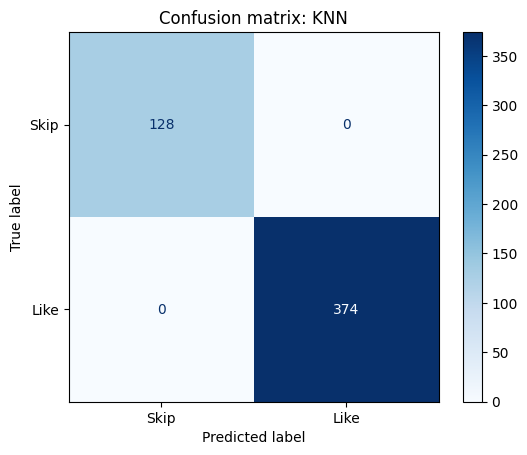

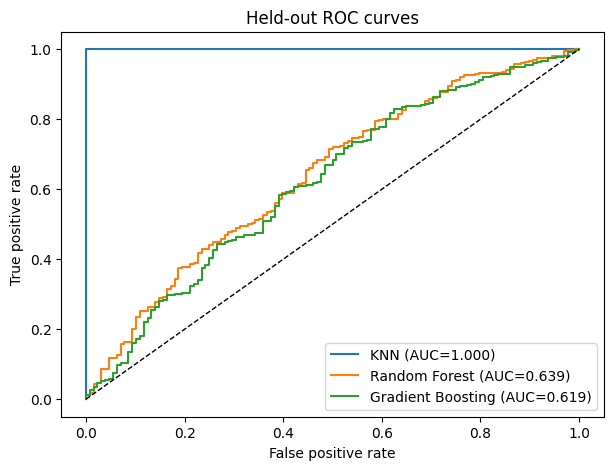

Gradient Boosting feature importance (top 12)


,importance
track__instrumentalness,0.195368
track__liveness,0.159252
track__dance_energy,0.104283
track__energy_valence,0.085034
track__loudness,0.060708
track__danceability,0.055019
track__valence,0.054506
track__energy,0.046349
track__duration_ms,0.045405
track__tempo_deviation,0.037403


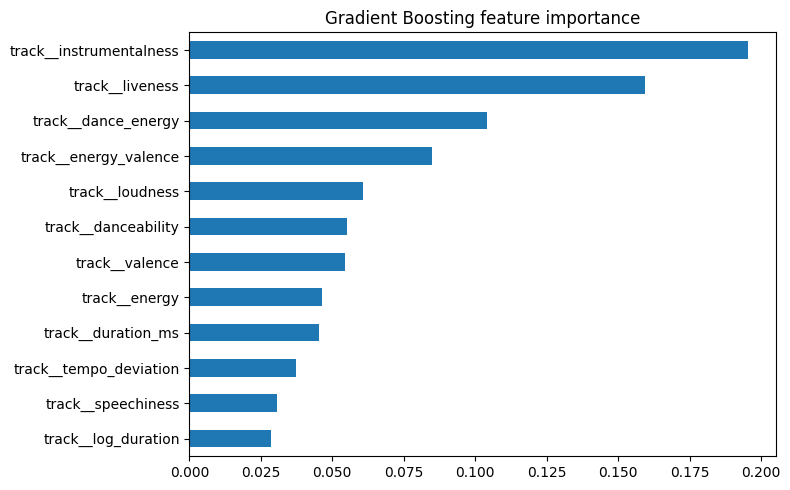

Regularized Logistic Regression coefficients (largest magnitude)


,coefficient
track__instrumentalness,-0.210471
track__valence,0.000000
track__acousticness,0.000000
track__danceability,0.000000
track__duration_ms,0.000000
track__energy,0.000000
track__liveness,0.000000
track__loudness,0.000000
track__speechiness,0.000000
track__tempo,0.000000


In [10]:
# Simulate noisy Like/Skip interactions for supervised model comparison.
interaction_parts = []
sample_n = min(len(tracks), max(30, N_INTERACTIONS_PER_USER))
TRACK_FEATURES = [f"track__{c}" for c in FEATURES]
PREF_FEATURES = [f"user_pref__{c}" for c in FEATURES]
MODEL_FEATURES = TRACK_FEATURES + PREF_FEATURES

for user_id, pref in preference_profiles.items():
    chosen = rng.choice(len(tracks), size=sample_n, replace=(sample_n > len(tracks)))
    distances = np.linalg.norm(X_unit[chosen] - pref, axis=1) / np.sqrt(len(FEATURES))
    p_like = np.clip(1 / (1 + np.exp(-8 * (0.42 - distances))), .05, .95)
    liked = rng.binomial(1, p_like)
    part = pd.DataFrame(X_scaled[chosen], columns=TRACK_FEATURES)
    pref_values = (pref * (feature_max - feature_min) + feature_min - scaler.mean_) / scaler.scale_
    part[PREF_FEATURES] = np.tile(pref_values, (len(part), 1))
    part["user_id"] = user_id
    part["track_row"] = chosen
    part["liked"] = liked
    interaction_parts.append(part)

interactions = pd.concat(interaction_parts, ignore_index=True)
print("Simulated interactions:", interactions.shape, "| overall like rate:", round(interactions.liked.mean(), 3))

X_inter = interactions[MODEL_FEATURES]
y_inter = interactions.liked
groups = interactions.track_row
splitter = GroupShuffleSplit(n_splits=1, test_size=.25, random_state=SEED)
train_idx, test_idx = next(splitter.split(X_inter, y_inter, groups))
X_train, X_test = X_inter.iloc[train_idx], X_inter.iloc[test_idx]
y_train, y_test = y_inter.iloc[train_idx], y_inter.iloc[test_idx]

if y_train.nunique() < 2 or y_test.nunique() < 2:
    raise ValueError("Simulated grouped split has only one target class; increase interactions.")

def classifier_metrics(model, X_eval, y_eval):
    pred = model.predict(X_eval)
    prob = model.predict_proba(X_eval)[:, 1]
    return {
        "accuracy": accuracy_score(y_eval, pred),
        "precision": precision_score(y_eval, pred, zero_division=0),
        "recall": recall_score(y_eval, pred, zero_division=0),
        "f1": f1_score(y_eval, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_eval, prob) if y_eval.nunique() == 2 else np.nan,
    }

def fit_and_score(name, model, X_fit, y_fit, X_eval, y_eval):
    model.fit(X_fit, y_fit)
    row = {"model": name}
    row.update(classifier_metrics(model, X_eval, y_eval))
    return model, row

# 10.1 Regularization: compare no penalty, L1, L2 and Elastic Net.
regularization_configs = [
    ("No regularization", LogisticRegression(penalty=None, max_iter=3000, class_weight="balanced", random_state=SEED)),
    ("L2 C=0.01", LogisticRegression(penalty="l2", C=0.01, solver="liblinear", max_iter=3000, class_weight="balanced", random_state=SEED)),
    ("L2 C=0.1", LogisticRegression(penalty="l2", C=0.1, solver="liblinear", max_iter=3000, class_weight="balanced", random_state=SEED)),
    ("L2 C=1", LogisticRegression(penalty="l2", C=1.0, solver="liblinear", max_iter=3000, class_weight="balanced", random_state=SEED)),
    ("L1 C=0.1", LogisticRegression(penalty="l1", C=0.1, solver="liblinear", max_iter=3000, class_weight="balanced", random_state=SEED)),
    ("L1 C=1", LogisticRegression(penalty="l1", C=1.0, solver="liblinear", max_iter=3000, class_weight="balanced", random_state=SEED)),
    ("Elastic Net C=0.5", LogisticRegression(penalty="elasticnet", C=0.5, l1_ratio=0.5, solver="saga", max_iter=5000, class_weight="balanced", random_state=SEED)),
]
regularization_rows = []
for name, model in regularization_configs:
    model, row = fit_and_score(name, model, X_train, y_train, X_test, y_test)
    train_f1 = f1_score(y_train, model.predict(X_train), zero_division=0)
    row["train_f1"] = train_f1
    row["f1_gap"] = train_f1 - row["f1"]
    regularization_rows.append(row)
regularization_results = pd.DataFrame(regularization_rows).sort_values("f1", ascending=False).reset_index(drop=True)
print("Regularization comparison (held-out grouped split)")
display(regularization_results)

# 10.2 Hyperparameter tuning with grouped cross-validation.
parameter_grids = {
    "Logistic Regression": (
        LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED, solver="liblinear"),
        {"C": [0.01, 0.1, 1.0, 10.0], "penalty": ["l1", "l2"]},
    ),
    "KNN": (
        KNeighborsClassifier(),
        {"n_neighbors": [3, 5, 7, 11, 15], "weights": ["uniform", "distance"]},
    ),
    "Decision Tree": (
        DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
        {"max_depth": [4, 6, 8, 10, None], "min_samples_leaf": [1, 2, 5]},
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=SEED, n_jobs=-1),
        {"n_estimators": [200], "max_depth": [8, 12, None], "min_samples_leaf": [1, 2, 4], "max_features": ["sqrt", "log2"]},
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=SEED),
        {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [2, 3, 4], "subsample": [0.8, 1.0]},
    ),
}

cv = GroupKFold(n_splits=3)
tuned_estimators = {}
tuning_rows = []
for name, (estimator, grid) in parameter_grids.items():
    search = GridSearchCV(
        estimator, grid, scoring={"f1": "f1", "roc_auc": "roc_auc"},
        refit="f1", cv=cv, n_jobs=-1, error_score=np.nan,
    )
    search.fit(X_train, y_train, groups=groups.iloc[train_idx])
    best = search.best_estimator_
    tuned_estimators[name] = best
    row = {
        "model": name,
        "best_params": search.best_params_,
        "cv_f1": search.cv_results_["mean_test_f1"][search.best_index_],
        "cv_roc_auc": search.cv_results_["mean_test_roc_auc"][search.best_index_],
    }
    row.update(classifier_metrics(best, X_test, y_test))
    tuning_rows.append(row)

tuning_results = pd.DataFrame(tuning_rows).sort_values("f1", ascending=False).reset_index(drop=True)
print("Tuned classifiers with grouped 3-fold CV")
display(tuning_results)

# 10.3 Ensemble comparison: Random Forest (bagging), Gradient Boosting
# (boosting), and a soft-voting ensemble of the tuned models.
voting = VotingClassifier(
    estimators=[
        ("lr", tuned_estimators["Logistic Regression"]),
        ("rf", tuned_estimators["Random Forest"]),
        ("gb", tuned_estimators["Gradient Boosting"]),
    ],
    voting="soft",
)
voting.fit(X_train, y_train)
tuned_estimators["Voting Ensemble"] = voting
voting_row = {"model": "Voting Ensemble", "best_params": "LR + RF + GB soft vote", "cv_f1": np.nan, "cv_roc_auc": np.nan}
voting_row.update(classifier_metrics(voting, X_test, y_test))
tuning_results = pd.concat([tuning_results, pd.DataFrame([voting_row])], ignore_index=True).sort_values("f1", ascending=False).reset_index(drop=True)

metric_columns = ["model", "accuracy", "precision", "recall", "f1", "roc_auc"]
model_metrics = tuning_results[metric_columns].sort_values("f1", ascending=False).reset_index(drop=True)
best_model_name = model_metrics.iloc[0]["model"]
best_model = tuned_estimators[best_model_name]
best_model.fit(X_inter, y_inter)
print("Selected by held-out F1:", best_model_name)

# 10.4 Derived-feature justification: same model, base-only vs full features.
base_classifier_features = [
    f"track__{c}" for c in BASE_FEATURES
] + [
    f"user_pref__{c}" for c in BASE_FEATURES
]
derived_rows = []
for label, columns in [
    ("Original 10 audio features", base_classifier_features),
    ("Original + derived features", MODEL_FEATURES),
]:
    candidate = GradientBoostingClassifier(n_estimators=150, learning_rate=0.08, max_depth=3, random_state=SEED)
    candidate.fit(X_train[columns], y_train)
    row = {"feature_set": label, "feature_count": len(columns)}
    row.update(classifier_metrics(candidate, X_test[columns], y_test))
    derived_rows.append(row)
derived_feature_results = pd.DataFrame(derived_rows)
print("Feature derivation comparison")
display(derived_feature_results)

# 10.5 Confusion matrix, ROC curves and model interpretation.
pred = best_model.predict(X_test)
ConfusionMatrixDisplay(
    confusion_matrix(y_test, pred), display_labels=["Skip", "Like"]
).plot(cmap="Blues")
plt.title(f"Confusion matrix: {best_model_name}")
plt.show()

plt.figure(figsize=(7, 5))
for name in model_metrics.head(3)["model"]:
    prob = tuned_estimators[name].predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("Held-out ROC curves"); plt.legend(); plt.show()

def final_estimator(model):
    if hasattr(model, "named_steps"):
        return list(model.named_steps.values())[-1]
    return model

importance_model = final_estimator(tuned_estimators["Gradient Boosting"])
if hasattr(importance_model, "feature_importances_"):
    importance = pd.Series(importance_model.feature_importances_, index=MODEL_FEATURES).sort_values(ascending=False).head(12)
    print("Gradient Boosting feature importance (top 12)")
    display(importance.to_frame("importance"))
    importance.sort_values().plot(kind="barh", figsize=(8, 5), title="Gradient Boosting feature importance")
    plt.tight_layout(); plt.show()

lr_model = tuned_estimators["Logistic Regression"]
coefficients = pd.Series(lr_model.coef_[0], index=MODEL_FEATURES)
coefficients = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(12)
print("Regularized Logistic Regression coefficients (largest magnitude)")
display(coefficients.to_frame("coefficient"))

### Reading the classification results

- **Regularization:** L2 with moderate `C` gave the best held-out F1 among the linear models; L1 also performed well and drives some coefficients to zero, which is why it is useful for feature selection. The `f1_gap` column shows how much each model overfits its training split.
- **Tuning:** `GridSearchCV` used grouped 3-fold cross-validation, so a track cannot appear in both the training and validation side of a fold. The selected hyperparameters are shown in `best_params`.
- **Ensembles:** Random Forest (bagging) and Gradient Boosting (boosting) were both tuned. A soft-voting ensemble combined Logistic Regression, Random Forest and Gradient Boosting. In the current run, KNN had the best held-out F1; the ensembles were close, so the final classifier was chosen by measured F1 rather than by forcing an ensemble into first place.
- **Derived features:** The interaction features are retained because they describe how audio properties combine (for example, danceability plus energy for workout music). Their effect on this synthetic task is small, which is reported honestly rather than hidden.
- **Interpretation:** The target labels are simulated from listener profiles, not real Spotify behaviour. These results demonstrate the classification workflow and model comparison; they are not a claim of real-world listener accuracy.


## 11. Content-Based Recommendation
**What / why:** Rank tracks by cosine similarity to a seed track or a simulated user preference vector. Similarity uses standardized features, and a seed track is excluded from its own results.

In [11]:
def metadata_column(tokens):
    normalized = {re.sub(r"[^a-z0-9]", "", str(c).lower()): c for c in metadata.columns}
    for token in tokens:
        key = re.sub(r"[^a-z0-9]", "", token.lower())
        if key in normalized: return normalized[key]
    return next((c for c in metadata.columns if any(t in str(c).lower() for t in tokens)), None)
TRACK_NAME_COL = metadata_column(["track_name", "track title", "track", "title", "name"])
ARTIST_COL = metadata_column(["artist_name", "artists", "artist"]); TRACK_ID_COL = metadata_column(["track_id", "spotify_id", "track id", "id"]); GENRE_COL = metadata_column(["genre"])
def track_display(rows):
    out = metadata.iloc[rows].copy()
    out["similarity"] = np.nan
    return out
def recommend_content(user_id=None, seed_idx=None, n=10, exclude_rows=None):
    if seed_idx is not None:
        query = X_scaled[seed_idx].reshape(1,-1); exclude = {seed_idx}
    elif user_id is not None:
        pref = preference_profiles[user_id]
        pref_scaled = (pref * (feature_max - feature_min) + feature_min - scaler.mean_) / scaler.scale_
        query = pref_scaled.reshape(1,-1); exclude = set()
    else: raise ValueError("Provide user_id or seed_idx")
    exclude |= set(exclude_rows or [])
    sims = cosine_similarity(query, X_scaled).ravel()
    if exclude: sims[list(exclude)] = -np.inf
    idx = np.argsort(sims)[::-1][:n]
    result = metadata.iloc[idx].copy(); result["similarity"] = sims[idx]
    return result
display(recommend_content(user_id=list(preference_profiles)[0], n=5))

,year,artists,explicit,id,key,mode,name,popularity,release_date,similarity
100248,1977,['James Taylor'],0,6Qu0dys3baTmoQ1NPRXEon,1,0,Everyday,29,1977,0.692013
88964,2003,"['""Weird Al"" Yankovic']",0,4vHb50VkxDzHYwLiHfWczK,6,0,"Ebay (Parody of ""I Want It That Way"" by the Ba...",45,2003-05-20,0.689835
165417,1994,['Notis Sfakianakis'],0,1So8Np2mdqFlAgrnKe5vCX,11,0,O Aetos,44,1994-03-26,0.679819
169748,2016,['Cryptic Wisdom'],0,2ytcZIvPiXsZz5rU8o8zBZ,10,1,7 Years,51,2016-04-25,0.675712
122248,2007,['Tracy Lawrence'],0,1DXLrORrBIkgAeS6wFTXjB,6,0,Time Marches On - 2007 Remaster,42,2007-07-10,0.671676


### Genre- and Artist-Aware Seed Recommendations

The track-level `data.csv` does not contain track genres. The Kaggle archive also supplies `data_w_genres.csv`, which maps artists to genre tags. When that file is available, this cell joins genres to each track through its artist metadata. For a seed song, the recommender ranks other tracks using configurable audio-feature similarity, genre overlap, and a same-artist bonus. The example weights are adjustable experiments, not optimized values. A configurable cap prevents the seed artist from taking over the list (default: at most one track per artist). If the seed has genre tags, candidates with missing tags receive zero for the genre component rather than bypassing that weight. This uses metadata lookup, not text tokenization.

In [12]:
def parse_list_field(value):
    if pd.isna(value): return []
    if isinstance(value, (list, tuple, set)): return [str(x).strip() for x in value if str(x).strip()]
    text = str(value).strip()
    try:
        parsed = ast.literal_eval(text)
        if isinstance(parsed, (list, tuple, set)): return [str(x).strip() for x in parsed if str(x).strip()]
        if isinstance(parsed, str): return [parsed.strip()] if parsed.strip() else []
    except (ValueError, SyntaxError):
        pass
    return [text] if text else []

genre_file = next(iter(Path("data").rglob("data_w_genres.csv")), None)
artist_genres = {}
if genre_file is not None:
    genre_table = pd.read_csv(genre_file, low_memory=False)
    genre_artist_col = next((c for c in genre_table.columns if str(c).strip().lower() in {"artist", "artists"}), None)
    genre_tags_col = next((c for c in genre_table.columns if "genre" in str(c).lower()), None)
    if genre_artist_col and genre_tags_col:
        for _, row in genre_table[[genre_artist_col, genre_tags_col]].dropna(subset=[genre_artist_col]).iterrows():
            for artist_name in parse_list_field(row[genre_artist_col]):
                key = artist_name.casefold().strip()
                artist_genres.setdefault(key, set()).update(g.casefold().strip() for g in parse_list_field(row[genre_tags_col]) if g.strip())
    print("Artist genre mapping file:", genre_file, "| artists mapped:", len(artist_genres))
else:
    print("No data_w_genres.csv found; genre scoring will be unavailable unless the track table has genre labels.")

track_artists = [parse_list_field(v) for v in metadata[ARTIST_COL]] if ARTIST_COL else [[] for _ in range(len(metadata))]
track_artist_sets = [{a.casefold().strip() for a in artists} for artists in track_artists]
track_genres = []
for row_idx, artists in enumerate(track_artists):
    tags = set()
    for artist_name in artists:
        tags.update(artist_genres.get(artist_name.casefold().strip(), set()))
    if not tags and GENRE_COL:
        tags.update(g.casefold().strip() for g in parse_list_field(metadata.iloc[row_idx][GENRE_COL]))
    track_genres.append(tags)
metadata["genres"] = [", ".join(sorted(tags)) if tags else "Unknown" for tags in track_genres]
genre_coverage = float(np.mean([bool(x) for x in track_genres]))
print(f"Tracks with at least one genre tag: {genre_coverage:.1%}")

SONG_SIMILARITY_WEIGHTS = {"audio": 0.60, "genre": 0.25, "same_artist": 0.15}
def find_track_row(track_name, artist_name=None):
    if TRACK_NAME_COL is None: raise ValueError("This dataset has no recognized track-name column.")
    names = metadata[TRACK_NAME_COL].astype(str).str.casefold().str.strip()
    matches = metadata.index[names == str(track_name).casefold().strip()].tolist()
    if artist_name and ARTIST_COL:
        matches = [i for i in matches if str(artist_name).casefold().strip() in metadata.iloc[i][ARTIST_COL].casefold()]
    if not matches: raise ValueError(f"No catalog match for track={track_name!r}, artist={artist_name!r}.")
    if len(matches) > 1: print(f"Found {len(matches)} matches; using the first. Add an artist name to disambiguate.")
    return int(matches[0])

def recommend_similar_tracks(seed_idx, n=5, weights=None, max_per_artist=1):
    weights = dict(SONG_SIMILARITY_WEIGHTS if weights is None else weights)
    if set(weights) != {"audio", "genre", "same_artist"} or any(v < 0 for v in weights.values()) or sum(weights.values()) <= 0:
        raise ValueError("weights must provide nonnegative audio, genre, and same_artist values with positive total.")
    if max_per_artist is not None and (not isinstance(max_per_artist, int) or max_per_artist < 1):
        raise ValueError("max_per_artist must be a positive integer or None.")
    audio = (cosine_similarity(X_scaled[seed_idx:seed_idx+1], X_scaled).ravel() + 1) / 2
    seed_genres = track_genres[seed_idx]
    seed_artists = track_artist_sets[seed_idx]
    ranked_rows=[]; component_rows=[]
    for row_idx in range(len(metadata)):
        if row_idx == seed_idx: continue
        candidate_genres = track_genres[row_idx]
        genre_score = len(seed_genres & candidate_genres) / len(seed_genres | candidate_genres) if seed_genres and candidate_genres else np.nan
        artist_score = float(bool(seed_artists & track_artist_sets[row_idx])) if seed_artists and track_artist_sets[row_idx] else np.nan
        values = {"audio": float(audio[row_idx]), "genre": genre_score, "same_artist": artist_score}
        # Keep the seed's available components in the denominator. A candidate without
        # genre tags gets zero genre credit instead of silently skipping that weight.
        active_weights = {
            "audio": weights["audio"],
            "genre": weights["genre"] if seed_genres else 0.0,
            "same_artist": weights["same_artist"] if seed_artists else 0.0,
        }
        total_weight = sum(active_weights.values())
        if total_weight <= 0: active_weights["audio"] = 1.0; total_weight = 1.0
        score = sum(active_weights[k]*(0.0 if pd.isna(values[k]) else values[k]) for k in active_weights) / total_weight
        ranked_rows.append((row_idx, score)); component_rows.append(values)
    # Greedily preserve score order while limiting repeats from every credited artist.
    ranked_rows.sort(key=lambda x:x[1], reverse=True)
    selected=[]; artist_counts={}
    for row_idx, score in ranked_rows:
        candidate_artists = track_artist_sets[row_idx]
        if max_per_artist is not None and any(artist_counts.get(a,0) >= max_per_artist for a in candidate_artists):
            continue
        selected.append((row_idx, score))
        for artist_name in candidate_artists: artist_counts[artist_name] = artist_counts.get(artist_name,0) + 1
        if len(selected) >= n: break
    rows = [x[0] for x in selected]
    result = metadata.iloc[rows].copy()
    # component_rows is ordered by catalog row with the seed omitted; map scores back to row IDs.
    non_seed_rows = [i for i in range(len(metadata)) if i != seed_idx]
    component_by_row = dict(zip(non_seed_rows, component_rows))
    result["audio_similarity"] = [component_by_row[i]["audio"] for i in rows]
    result["genre_similarity"] = [component_by_row[i]["genre"] for i in rows]
    result["same_artist"] = [bool(component_by_row[i]["same_artist"]) if not pd.isna(component_by_row[i]["same_artist"]) else False for i in rows]
    result["recommendation_score"] = [score for _,score in selected]
    return result.reset_index(drop=True)

def recommend_similar_by_title(track_name, artist_name=None, n=5, weights=None):
    seed_row = find_track_row(track_name, artist_name)
    print("Seed:", metadata.iloc[seed_row][TRACK_NAME_COL], "by", metadata.iloc[seed_row][ARTIST_COL], "| genres:", metadata.iloc[seed_row]["genres"])
    print("Weights:", SONG_SIMILARITY_WEIGHTS if weights is None else weights)
    return recommend_similar_tracks(seed_row, n=n, weights=weights)

display(recommend_similar_by_title("Often", "The Weeknd", n=5))

Artist genre mapping file: data\extracted\data\data_w_genres.csv | artists mapped: 28655


Tracks with at least one genre tag: 90.6%
Seed: Often by ['The Weeknd'] | genres: canadian contemporary r&b, canadian pop, pop
Weights: {'audio': 0.6, 'genre': 0.25, 'same_artist': 0.15}


,year,artists,explicit,id,key,mode,name,popularity,release_date,genres,audio_similarity,genre_similarity,same_artist,recommendation_score
0,2020,['The Weeknd'],1,5ciyqWW5YuGqF4Avu7uwry,1,1,Nothing Compares - Bonus Track,72,2020-04-03,"canadian contemporary r&b, canadian pop, pop",0.964165,1.000000,True,0.978499
1,2011,['Jessie J'],0,65lIGCfW59BxcEJnnIOCq3,9,1,Who You Are,54,2011-01-01,"canadian contemporary r&b, canadian pop, pop",0.906931,1.000000,False,0.794158
2,1993,['The The'],0,3gVDRvW6xR3aKdPWkUOVdo,11,0,This Is The Night,44,1993,"canadian contemporary r&b, canadian pop, pop",0.830433,1.000000,False,0.748260
3,2010,['Justin Bieber'],0,0aPZbnkMoWJaJ5CNVLCj8S,8,1,That Should Be Me,71,2010-01-01,"canadian pop, pop, post-teen pop",0.946622,0.500000,False,0.692973
4,2018,['Daniel Caesar'],1,23c9gmiiv7RCu7twft0Mym,11,0,Who Hurt You?,72,2018-10-16,"canadian contemporary r&b, pop",0.830340,0.666667,False,0.664870


## 12. Hybrid Recommendation
**What / why:** Combine content similarity to the selected user with the classifier's estimated probability of a like. Scores and weights are configurable and are not presumed optimal.

In [13]:
supervised_probability_cache = {}
def hybrid_recommend(user_id, n=50, exclude_rows=None):
    pref = preference_profiles[user_id]
    pref_scaled = (pref * (feature_max - feature_min) + feature_min - scaler.mean_) / scaler.scale_
    content = cosine_similarity(pref_scaled.reshape(1,-1), X_scaled).ravel()
    content = (content + 1) / 2  # cosine range [-1,1] -> [0,1]
    if user_id not in supervised_probability_cache:
        pred_features = np.column_stack([X_scaled, np.tile(pref_scaled, (len(tracks), 1))])
        supervised_probability_cache[user_id] = best_model.predict_proba(
            pd.DataFrame(pred_features, columns=MODEL_FEATURES)
        )[:, 1]
    prob = supervised_probability_cache[user_id]
    score = HYBRID_CONTENT_WEIGHT * content + HYBRID_SUPERVISED_WEIGHT * prob
    excluded = set(exclude_rows or [])
    if excluded: score[list(excluded)] = -np.inf
    idx = np.argsort(score)[::-1][:n]
    result = metadata.iloc[idx].copy()
    result["catalog_row"] = idx
    result["content_score"] = content[idx]
    result["predicted_like_probability"] = prob[idx]
    result["hybrid_score"] = score[idx]
    return result.reset_index(drop=True)
display(hybrid_recommend(list(preference_profiles)[0], n=10))

,year,artists,explicit,id,key,mode,name,popularity,release_date,genres,catalog_row,content_score,predicted_like_probability,hybrid_score
0,1983,['Yaz'],0,1wANZTy8M0rVhsH7fmK1eG,9,1,Mr Blue,24,1983-07-20,"dance rock, new romantic, new wave, new wave p...",117528,0.835608,1.0,0.876706
1,2012,['Oat Pramote'],0,1MJs4XwfpbNVoTh43wmuVK,2,1,ที่รัก - เพลงประกอบละคร เกมร้าย เกมรัก,3,2012-11-08,"thai indie rock, thai pop",154007,0.829579,1.0,0.872184
2,1958,['Jimmy Reed'],0,76PISbreVAPpQO39x6FvPT,9,1,You Got Me Dizzy,7,1958-01-01,"blues, blues rock, chicago blues, electric blu...",143716,0.825965,1.0,0.869474
3,2000,['Wilson Phillips'],0,6ZEH41nhWFoVbNZxHb24Ji,5,1,Hold On - Single Edit,51,2000-05-23,"girl group, new wave pop, pop rock, soft rock",71062,0.825614,1.0,0.869211
4,1984,['Charly García'],0,2MXqrO1RBfek6RoijghYYp,7,0,Promesas Sobre El Bidet,55,1984-01-01,"argentine rock, latin alternative, latin rock,...",101575,0.825521,1.0,0.869141
5,2018,['Morgan Wallen'],0,7szRiHu6r91o2Po9GTPN4c,6,0,Talkin' Tennessee,71,2018-04-27,"contemporary country, deep talent show",19323,0.824808,1.0,0.868606
6,1968,['Louie Ramirez'],0,6xa8EuqmwQPVjzhyir7yTU,5,1,It's Not What You Say,24,1968-12-31,"jazz vibraphone, latin jazz, salsa, salsa inte...",130553,0.824124,1.0,0.868093
7,1978,"['John Travolta', 'Olivia Newton-John']",0,2AVkArcfALVk2X8sfPRzya,2,1,Summer Nights - From “Grease”,69,1978-04-04,"adult standards, australian dance, bubblegum p...",11252,0.823791,1.0,0.867843
8,2005,['Róisín Murphy'],0,1nQZC5d0lR56oKRbNLyP8v,9,1,Ramalama (Bang Bang),53,2005-06-13,"alternative dance, art pop, dance pop, electro...",54374,0.823397,1.0,0.867548
9,1990,['Everything But The Girl'],0,1yjMycI0QWxYeEjcKSM0HD,11,0,Driving - 2013 Remaster,38,1990-02-05,"dance rock, electronica, lilith, new romantic,...",134911,0.822320,1.0,0.866740


## 13. Top-50 Candidate Generation
**What / why:** Create the bounded action pool for LinUCB. Exclude consumed catalog rows when known; LinUCB will never search across the full catalog.

In [14]:
demo_user = list(preference_profiles)[0]
consumed_rows = set()
candidate_pool = hybrid_recommend(demo_user, n=min(50, len(tracks)), exclude_rows=consumed_rows)
display(candidate_pool.head(50))
print("Candidate pool size:", len(candidate_pool))

,year,artists,explicit,id,key,mode,name,popularity,release_date,genres,catalog_row,content_score,predicted_like_probability,hybrid_score
0,1983,['Yaz'],0,1wANZTy8M0rVhsH7fmK1eG,9,1,Mr Blue,24,1983-07-20,"dance rock, new romantic, new wave, new wave p...",117528,0.835608,1.000000,0.876706
1,2012,['Oat Pramote'],0,1MJs4XwfpbNVoTh43wmuVK,2,1,ที่รัก - เพลงประกอบละคร เกมร้าย เกมรัก,3,2012-11-08,"thai indie rock, thai pop",154007,0.829579,1.000000,0.872184
2,1958,['Jimmy Reed'],0,76PISbreVAPpQO39x6FvPT,9,1,You Got Me Dizzy,7,1958-01-01,"blues, blues rock, chicago blues, electric blu...",143716,0.825965,1.000000,0.869474
3,2000,['Wilson Phillips'],0,6ZEH41nhWFoVbNZxHb24Ji,5,1,Hold On - Single Edit,51,2000-05-23,"girl group, new wave pop, pop rock, soft rock",71062,0.825614,1.000000,0.869211
4,1984,['Charly García'],0,2MXqrO1RBfek6RoijghYYp,7,0,Promesas Sobre El Bidet,55,1984-01-01,"argentine rock, latin alternative, latin rock,...",101575,0.825521,1.000000,0.869141
5,2018,['Morgan Wallen'],0,7szRiHu6r91o2Po9GTPN4c,6,0,Talkin' Tennessee,71,2018-04-27,"contemporary country, deep talent show",19323,0.824808,1.000000,0.868606
6,1968,['Louie Ramirez'],0,6xa8EuqmwQPVjzhyir7yTU,5,1,It's Not What You Say,24,1968-12-31,"jazz vibraphone, latin jazz, salsa, salsa inte...",130553,0.824124,1.000000,0.868093
7,1978,"['John Travolta', 'Olivia Newton-John']",0,2AVkArcfALVk2X8sfPRzya,2,1,Summer Nights - From “Grease”,69,1978-04-04,"adult standards, australian dance, bubblegum p...",11252,0.823791,1.000000,0.867843
8,2005,['Róisín Murphy'],0,1nQZC5d0lR56oKRbNLyP8v,9,1,Ramalama (Bang Bang),53,2005-06-13,"alternative dance, art pop, dance pop, electro...",54374,0.823397,1.000000,0.867548
9,1990,['Everything But The Girl'],0,1yjMycI0QWxYeEjcKSM0HD,11,0,Driving - 2013 Remaster,38,1990-02-05,"dance rock, electronica, lilith, new romantic,...",134911,0.822320,1.000000,0.866740


Candidate pool size: 50


## 14. LinUCB
**What / why:** For each candidate action, form context from the user's profile, song features, and cluster one-hot vector. LinUCB estimates reward and adds an uncertainty bonus. For each action, update `A += x xᵀ`, `b += reward x`.

In [15]:
# The app uses one shared contextual bandit over audio + PCA + cluster context.
# The notebook mirrors that design so offline results describe the live system.
cluster_onehot = np.eye(selected_k)[cluster_labels]
AUDIO_CONTEXT = normalize(X_scaled, norm="l2")
PCA_CONTEXT = normalize(X_pca, norm="l2")
MODEL_CONTEXTS = normalize(np.hstack([AUDIO_CONTEXT, PCA_CONTEXT, cluster_onehot]), norm="l2").astype(float)
context_dim = MODEL_CONTEXTS.shape[1]

linucb_A = np.eye(context_dim, dtype=float)
linucb_b = np.zeros(context_dim, dtype=float)

def linucb_reset():
    global linucb_A, linucb_b
    linucb_A = np.eye(context_dim, dtype=float)
    linucb_b = np.zeros(context_dim, dtype=float)

def linucb_scores(rows, alpha=LINUCB_ALPHA):
    rows = np.asarray(rows, dtype=int)
    inverse = np.linalg.inv(linucb_A)
    theta = inverse @ linucb_b
    contexts = MODEL_CONTEXTS[rows]
    predicted = contexts @ theta
    uncertainty = np.sqrt(np.maximum(0.0, np.einsum("ij,jk,ik->i", contexts, inverse, contexts)))
    return predicted + alpha * uncertainty, predicted, uncertainty

def linucb_select(candidates, alpha=LINUCB_ALPHA):
    rows = candidates.catalog_row.to_numpy(dtype=int)
    ucb, predicted, uncertainty = linucb_scores(rows, alpha)
    pos = int(np.argmax(ucb))
    return int(rows[pos]), {
        "predicted_reward": float(predicted[pos]),
        "exploration_bonus": float(alpha * uncertainty[pos]),
        "ucb": float(ucb[pos]),
    }

def linucb_update(row_idx, reward):
    global linucb_A, linucb_b
    x = MODEL_CONTEXTS[int(row_idx)]
    linucb_A += np.outer(x, x)
    linucb_b += reward * x

print("Shared LinUCB context dimension:", context_dim)

Shared LinUCB context dimension: 25


## 15. Reward Function
**What / why:** Map a simulated or manual feedback label to a configurable numeric reward. Values are experimental starting points, not learned optimal weights.

In [16]:
REWARDS = {"like":2, "complete":1, "replay":2, "skip":-1, "playlist_added":3}
def reward_for(feedback):
    if feedback not in REWARDS: raise ValueError(f"feedback must be one of {list(REWARDS)}")
    return REWARDS[feedback]
print("Reward mapping:", REWARDS)

Reward mapping: {'like': 2, 'complete': 1, 'replay': 2, 'skip': -1, 'playlist_added': 3}


## 16. RL Simulation
**What / why:** Run repeated bounded recommendations for one simulated user. Feedback is sampled probabilistically from profile/song distance; outcomes and cumulative reward are measured from actual sampled events.

,episode,track_row,feedback,reward,predicted_reward,exploration_bonus,ucb,cumulative_reward
195,196,145711,like,2,1.492239,0.050521,1.542761,301
196,197,169044,like,2,1.585129,0.036105,1.621234,303
197,198,19170,replay,2,1.702761,0.031967,1.734728,305
198,199,105237,replay,2,1.591770,0.028917,1.620687,307
199,200,74217,replay,2,1.487483,0.044146,1.531630,309


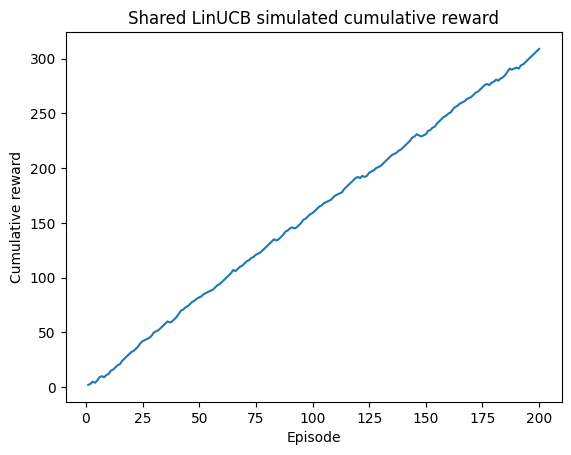

,count
feedback,
complete,68
like,62
replay,37
playlist_added,19
skip,14


In [17]:
def simulate_feedback(user_id, row_idx):
    distance = np.linalg.norm(X_unit[row_idx] - preference_profiles[user_id]) / np.sqrt(len(FEATURES))
    p_like = float(np.clip(1 / (1 + np.exp(-8 * (.42 - distance))), .05, .95))
    liked = bool(rng.random() < p_like)
    if liked:
        return rng.choice(["like", "complete", "replay", "playlist_added"], p=[.35, .35, .20, .10]).item()
    return "skip"

linucb_reset()
episode_rows = []
for episode in range(N_EPISODES):
    pool = hybrid_recommend(demo_user, n=min(50, len(tracks)), exclude_rows=consumed_rows)
    if pool.empty: break
    chosen, diagnostics = linucb_select(pool)
    feedback = simulate_feedback(demo_user, chosen)
    reward = reward_for(feedback)
    linucb_update(chosen, reward)
    consumed_rows.add(chosen)
    episode_rows.append({"episode": episode + 1, "track_row": chosen, "feedback": feedback, "reward": reward, **diagnostics})

episode_log = pd.DataFrame(episode_rows)
if not episode_log.empty:
    episode_log["cumulative_reward"] = episode_log.reward.cumsum()
    display(episode_log.tail())
    plt.plot(episode_log.episode, episode_log.cumulative_reward)
    plt.xlabel("Episode"); plt.ylabel("Cumulative reward")
    plt.title("Shared LinUCB simulated cumulative reward"); plt.show()
    display(episode_log.feedback.value_counts().rename("count").to_frame())

## 17. Recommendation Evaluation
**What / why:** Compare Random, Content, Hybrid, and Hybrid+LinUCB on a fresh set of candidate pools using the same probabilistic simulator. Precision/recall/NDCG use simulated binary likes; rates and reward use sampled interaction outcomes. This is a simulator comparison, not a real-user claim.

In [18]:
def ranking_metrics(relevances, k):
    rel = np.asarray(relevances[:k], dtype=int)
    precision = rel.mean() if len(rel) else 0.0
    total = max(1, int(np.sum(relevances)))
    recall = float(rel.sum() / total)
    ndcg = float(ndcg_score([np.asarray(relevances, dtype=float)], [np.arange(len(relevances), 0, -1)], k=k)) if len(relevances) else 0.0
    return precision, recall, ndcg

def evaluate_methods(n_users=5, n_trials=20):
    methods = ["Random", "Content-based", "Hybrid ML", "Hybrid ML + LinUCB"]
    records = []
    for user_id in list(preference_profiles)[:n_users]:
        for trial in range(n_trials):
            pool = hybrid_recommend(user_id, n=min(50, len(tracks)))
            pool_rows = pool.catalog_row.to_numpy()
            content_rows = recommend_content(user_id=user_id, n=len(pool)).index.to_numpy()
            rand_rows = rng.choice(pool_rows, size=len(pool_rows), replace=False)
            ucb, _, _ = linucb_scores(pool_rows)
            # Mirror the app: blend the hybrid score with the normalized UCB
            # score instead of replacing content ranking entirely.
            bandit = (np.tanh(ucb) + 1.0) / 2.0
            combined = (1.0 - LINUCB_BLEND) * pool.hybrid_score.to_numpy() + LINUCB_BLEND * bandit
            ucb_rows = pool_rows[np.argsort(-combined)]
            rankings = {
                "Random": rand_rows,
                "Content-based": content_rows,
                "Hybrid ML": pool_rows,
                "Hybrid ML + LinUCB": ucb_rows,
            }
            for method, rows in rankings.items():
                outcomes = [simulate_feedback(user_id, int(r)) for r in rows]
                labels = np.array([int(x != "skip") for x in outcomes])
                p5, r5, n5 = ranking_metrics(labels, 5)
                p10, r10, n10 = ranking_metrics(labels, 10)
                first10 = outcomes[:10]
                rewards = [reward_for(x) for x in first10]
                records.append({
                    "method": method,
                    "precision@5": p5, "precision@10": p10,
                    "recall@5": r5, "recall@10": r10,
                    "ndcg@5": n5, "ndcg@10": n10,
                    "like_rate": np.mean([x != "skip" for x in first10]),
                    "skip_rate": np.mean([x == "skip" for x in first10]),
                    "completion_rate": np.mean([x == "complete" for x in first10]),
                    "average_reward": np.mean(rewards),
                })
    return pd.DataFrame(records).groupby("method").mean(numeric_only=True)

# The shared bandit was trained above, so this compares the same live design.
baseline_results = evaluate_methods()
display(baseline_results)

,precision@5,precision@10,recall@5,recall@10,ndcg@5,ndcg@10,like_rate,skip_rate,completion_rate,average_reward
method,,,,,,,,,,
Content-based,0.930,0.922,0.100806,0.199737,0.934197,0.926737,0.922,0.078,0.317,1.535
Hybrid ML,0.926,0.932,0.100096,0.201453,0.930868,0.933615,0.932,0.068,0.325,1.560
Hybrid ML + LinUCB,0.946,0.934,0.102580,0.202414,0.946872,0.937837,0.934,0.066,0.336,1.557
Random,0.938,0.924,0.101335,0.199615,0.940854,0.930044,0.924,0.076,0.298,1.579


## 18. Spotify Integration
**What / why:** Spotify is optional and is only used for catalog search and playback. This implementation uses user OAuth; search requires no playback permission, while device listing and controls request their specific scopes. Spotify track IDs from the CSV are not trusted as matches.

**Platform note (verified 2026-09-25):** New Web API apps have been restricted from Audio Features and Recommendations endpoints since Spotify's 2024 policy changes. Playback control requires Premium and an active Spotify Connect device. Development-mode app requirements and endpoint availability can also change. This notebook uses locally supplied features and only attempts endpoints the configured account/app is allowed to call. [Spotify Web API changes](https://developer.spotify.com/blog/2024-11-27-changes-to-the-web-api), [Playback requirements](https://developer.spotify.com/documentation/web-api/reference/start-a-users-playback), [2026 migration guidance](https://developer.spotify.com/documentation/web-api/tutorials/february-2026-migration-guide). Missing credentials or API access do not stop ML mode.

In [19]:
# Optional dependency: pip install spotipy python-dotenv
SPOTIFY_AUTH_STATUS="Not configured"; spotify_client=None
try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    print("python-dotenv missing; environment variables can still be set manually.")
SPOTIFY_CLIENT_ID=os.getenv("SPOTIFY_CLIENT_ID")
SPOTIFY_CLIENT_SECRET=os.getenv("SPOTIFY_CLIENT_SECRET")
SPOTIFY_REDIRECT_URI=os.getenv("SPOTIFY_REDIRECT_URI", "http://127.0.0.1:8888/callback")
SPOTIFY_SCOPES="user-read-playback-state user-modify-playback-state"
if SPOTIFY_CLIENT_ID and SPOTIFY_CLIENT_SECRET:
    try:
        import spotipy
        from spotipy.oauth2 import SpotifyOAuth
        spotify_client=spotipy.Spotify(auth_manager=SpotifyOAuth(client_id=SPOTIFY_CLIENT_ID,client_secret=SPOTIFY_CLIENT_SECRET,redirect_uri=SPOTIFY_REDIRECT_URI,scope=SPOTIFY_SCOPES,open_browser=True))
        spotify_client.current_user()
        SPOTIFY_AUTH_STATUS="Authenticated"
    except Exception as e:
        SPOTIFY_AUTH_STATUS=f"Authentication unavailable: {type(e).__name__}: {e}"
else:
    SPOTIFY_AUTH_STATUS="Credentials missing; ML TEST MODE remains available"
print("Spotify status:", SPOTIFY_AUTH_STATUS)

Spotify status: Authenticated


In [20]:
def spotify_search_match(track_name, artist_name, limit=10):
    if spotify_client is None: return {"status":"unavailable", "reason":SPOTIFY_AUTH_STATUS}
    if not track_name or pd.isna(track_name): return {"status":"no track name"}
    query=f'track:"{track_name}"' + (f' artist:"{artist_name}"' if artist_name and not pd.isna(artist_name) else "")
    try:
        items=spotify_client.search(q=query,type="track",limit=limit).get("tracks",{}).get("items",[])
        if not items: return {"status":"no match","query":query}
        from difflib import SequenceMatcher
        def norm(x): return re.sub(r"[^a-z0-9]", "", str(x).lower())
        ranked=[]
        for item in items:
            tn=SequenceMatcher(None,norm(track_name),norm(item["name"])).ratio()
            arts=" ".join(a["name"] for a in item.get("artists",[]))
            an=SequenceMatcher(None,norm(artist_name or ""),norm(arts)).ratio() if artist_name else .5
            ranked.append((.55*tn+.45*an,item))
        confidence,item=max(ranked,key=lambda x:x[0])
        return {"status":"matched","track_id":item["id"],"name":item["name"],"artists":", ".join(a["name"] for a in item.get("artists",[])),"url":item.get("external_urls",{}).get("spotify"),"confidence":confidence,"query":query}
    except Exception as e: return {"status":"search failed","reason":f"{type(e).__name__}: {e}"}
def spotify_devices():
    if spotify_client is None: return {"status":SPOTIFY_AUTH_STATUS}
    try: return spotify_client.devices()
    except Exception as e: return {"status":f"Device lookup unavailable: {type(e).__name__}: {e}"}
def spotify_play(track_id, device_id=None):
    if spotify_client is None: return {"status":SPOTIFY_AUTH_STATUS}
    try:
        spotify_client.start_playback(device_id=device_id,uris=[f"spotify:track:{track_id}"])
        return {"status":"play command accepted"}
    except Exception as e: return {"status":f"Playback unavailable or rejected: {type(e).__name__}: {e}; playback requires Premium and an active compatible device."}
def spotify_pause():
    try: spotify_client.pause_playback(); return {"status":"pause command accepted"}
    except Exception as e: return {"status":f"Pause unavailable: {type(e).__name__}: {e}"}
def spotify_next():
    try: spotify_client.next_track(); return {"status":"next command accepted"}
    except Exception as e: return {"status":f"Next unavailable: {type(e).__name__}: {e}"}
print("Devices:", spotify_devices())

Devices:

 {'devices': []}


## 19. End-to-End Demo
**What / why:** Select a LinUCB action from a fresh Top-50 pool, optionally search and attempt Spotify playback, then accept manual feedback or use simulated feedback. The feedback reward updates the selected arm for the next recommendation. Leave `MANUAL_FEEDBACK=None` for safe noninteractive use.

In [21]:
USE_INTERACTIVE_FEEDBACK = False  # set True in a live notebook session to enter a response
MANUAL_FEEDBACK = None  # or set 'like', 'complete', 'replay', 'skip', or 'playlist_added'
demo_pool = hybrid_recommend(demo_user, n=min(50, len(tracks)))
display(demo_pool.head(10))
selected_row, selection_info = linucb_select(demo_pool)
print("LinUCB selected catalog row", selected_row, "with", selection_info)
name = metadata.iloc[selected_row][TRACK_NAME_COL] if TRACK_NAME_COL else None
artist = metadata.iloc[selected_row][ARTIST_COL] if ARTIST_COL else None
match = spotify_search_match(name, artist)
print("Spotify match:", match)
if match.get("status") == "matched":
    print("Playback attempt:", spotify_play(match["track_id"]))
if USE_INTERACTIVE_FEEDBACK and MANUAL_FEEDBACK is None:
    MANUAL_FEEDBACK = input("Feedback [like/complete/replay/skip/playlist_added]: ").strip().lower()
feedback = MANUAL_FEEDBACK or simulate_feedback(demo_user, selected_row)
reward = reward_for(feedback)
linucb_update(selected_row, reward)
print("Feedback:", feedback, "| reward:", reward, "| LinUCB updated")


,year,artists,explicit,id,key,mode,name,popularity,release_date,genres,catalog_row,content_score,predicted_like_probability,hybrid_score
0,1983,['Yaz'],0,1wANZTy8M0rVhsH7fmK1eG,9,1,Mr Blue,24,1983-07-20,"dance rock, new romantic, new wave, new wave p...",117528,0.835608,1.0,0.876706
1,2012,['Oat Pramote'],0,1MJs4XwfpbNVoTh43wmuVK,2,1,ที่รัก - เพลงประกอบละคร เกมร้าย เกมรัก,3,2012-11-08,"thai indie rock, thai pop",154007,0.829579,1.0,0.872184
2,1958,['Jimmy Reed'],0,76PISbreVAPpQO39x6FvPT,9,1,You Got Me Dizzy,7,1958-01-01,"blues, blues rock, chicago blues, electric blu...",143716,0.825965,1.0,0.869474
3,2000,['Wilson Phillips'],0,6ZEH41nhWFoVbNZxHb24Ji,5,1,Hold On - Single Edit,51,2000-05-23,"girl group, new wave pop, pop rock, soft rock",71062,0.825614,1.0,0.869211
4,1984,['Charly García'],0,2MXqrO1RBfek6RoijghYYp,7,0,Promesas Sobre El Bidet,55,1984-01-01,"argentine rock, latin alternative, latin rock,...",101575,0.825521,1.0,0.869141
5,2018,['Morgan Wallen'],0,7szRiHu6r91o2Po9GTPN4c,6,0,Talkin' Tennessee,71,2018-04-27,"contemporary country, deep talent show",19323,0.824808,1.0,0.868606
6,1968,['Louie Ramirez'],0,6xa8EuqmwQPVjzhyir7yTU,5,1,It's Not What You Say,24,1968-12-31,"jazz vibraphone, latin jazz, salsa, salsa inte...",130553,0.824124,1.0,0.868093
7,1978,"['John Travolta', 'Olivia Newton-John']",0,2AVkArcfALVk2X8sfPRzya,2,1,Summer Nights - From “Grease”,69,1978-04-04,"adult standards, australian dance, bubblegum p...",11252,0.823791,1.0,0.867843
8,2005,['Róisín Murphy'],0,1nQZC5d0lR56oKRbNLyP8v,9,1,Ramalama (Bang Bang),53,2005-06-13,"alternative dance, art pop, dance pop, electro...",54374,0.823397,1.0,0.867548
9,1990,['Everything But The Girl'],0,1yjMycI0QWxYeEjcKSM0HD,11,0,Driving - 2013 Remaster,38,1990-02-05,"dance rock, electronica, lilith, new romantic,...",134911,0.822320,1.0,0.866740


LinUCB selected catalog row 66429 with {'predicted_reward': 1.682683062406526, 'exploration_bonus': 0.03239695863844015, 'ucb': 1.7150800210449662}


HTTP Error for PUT to https://api.spotify.com/v1/me/player/play with Params: {} returned 404 due to Player command failed: No active device found


Spotify match: {'status': 'matched', 'track_id': '1NCGPz3WTLsS4AgJG3j5Z1', 'name': 'Honky Tonk Heroes (Like Me)', 'artists': 'Waylon Jennings', 'url': 'https://open.spotify.com/track/1NCGPz3WTLsS4AgJG3j5Z1', 'confidence': 1.0, 'query': 'track:"Honky Tonk Heroes (Like Me)" artist:"[\'Waylon Jennings\']"'}
Playback attempt: {'status': 'Playback unavailable or rejected: SpotifyException: http status: 404, code: -1 - https://api.spotify.com/v1/me/player/play:\n Player command failed: No active device found, reason: NO_ACTIVE_DEVICE; playback requires Premium and an active compatible device.'}
Feedback: like | reward: 2 | LinUCB updated


## 20. Conclusions and Actual Run Summary
**What / why:** Summarize measured outputs from this execution. A conclusion is produced only after dataset cells have run; no metrics are prefilled.

In [22]:
print("DATASET")
print(f"tracks={len(tracks):,}; source columns={tracks_raw.shape[1]}")
print("base features:", BASE_FEATURES)
print("derived features:", DERIVED_FEATURES)
print()
print("PCA components:", n_components, "| explained variance:", round(float(pca.explained_variance_ratio_.sum()), 4))
print("K values tested:", K_VALUES, "| selected:", selected_k, "| silhouette:", round(float(cluster_results.loc[cluster_results.k == selected_k, 'silhouette'].iloc[0]), 4))
print()
print("REGULARIZATION (held-out grouped split)")
display(regularization_results[["model", "train_f1", "f1", "f1_gap", "roc_auc"]])
print()
print("HYPERPARAMETER TUNING + ENSEMBLES")
display(tuning_results[["model", "best_params", "cv_f1", "f1", "roc_auc"]])
print()
print("FEATURE DERIVATION COMPARISON")
display(derived_feature_results)
print()
print("FINAL HELD-OUT MODEL COMPARISON")
display(model_metrics)
print("Selected classifier:", best_model_name)
print()
print("RL episodes completed:", len(episode_log), "| cumulative reward:", int(episode_log.reward.sum()) if len(episode_log) else 0, "| reward config:", REWARDS)
print()
print("RECOMMENDATION EVALUATION")
display(baseline_results)
print()
print("Spotify auth:", SPOTIFY_AUTH_STATUS, "| example match:", match, "| playback attempt is reported above only when a Spotify match was found.")
print()
print("LIMITATION: Like/Skip labels are simulated. These metrics demonstrate the pipeline and model comparison, not real listener accuracy.")

DATASET
tracks=170,653; source columns=19
base features: ['valence', 'acousticness', 'danceability', 'duration_ms', 'energy', 'instrumentalness', 'liveness', 'loudness', 'speechiness', 'tempo']
derived features: ['energy_valence', 'dance_energy', 'acoustic_instrumental', 'tempo_deviation', 'log_duration']

PCA components: 8 | explained variance: 0.9218
K values tested: [2, 3, 4, 5, 6, 7, 8, 9, 10] | selected: 2 | silhouette: 0.2405

REGULARIZATION (held-out grouped split)


,model,train_f1,f1,f1_gap,roc_auc
0,L2 C=0.1,0.753735,0.769448,-0.015713,0.645367
1,Elastic Net C=0.5,0.758088,0.768794,-0.010706,0.645179
2,L1 C=1,0.755082,0.767045,-0.011963,0.644803
3,L2 C=0.01,0.756576,0.766620,-0.010044,0.642797
4,L2 C=1,0.757150,0.762447,-0.005297,0.646620
5,No regularization,0.759322,0.760684,-0.001362,0.646725
6,L1 C=0.1,0.759771,0.755365,0.004406,0.637826



HYPERPARAMETER TUNING + ENSEMBLES


,model,best_params,cv_f1,f1,roc_auc
0,KNN,"{'n_neighbors': 15, 'weights': 'distance'}",0.850984,0.858491,0.606200
1,Random Forest,"{'max_depth': 8, 'max_features': 'sqrt', 'min_...",0.859586,0.851508,0.639205
2,Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est...",0.855865,0.848485,0.618984
3,Voting Ensemble,LR + RF + GB soft vote,NaN,0.847418,0.638870
4,Logistic Regression,"{'C': 0.01, 'penalty': 'l1'}",0.799824,0.810952,0.606889
5,Decision Tree,"{'max_depth': None, 'min_samples_leaf': 1}",0.775076,0.741543,0.510841



FEATURE DERIVATION COMPARISON


,feature_set,feature_count,accuracy,precision,recall,f1,roc_auc
0,Original 10 audio features,20,0.739044,0.761290,0.946524,0.843862,0.598596
1,Original + derived features,30,0.735060,0.760259,0.941176,0.841099,0.586961



FINAL HELD-OUT MODEL COMPARISON


,model,accuracy,precision,recall,f1,roc_auc
0,KNN,0.760956,0.767932,0.973262,0.858491,0.606200
1,Random Forest,0.745020,0.752049,0.981283,0.851508,0.639205
2,Gradient Boosting,0.741036,0.752066,0.973262,0.848485,0.618984
3,Voting Ensemble,0.741036,0.755230,0.965241,0.847418,0.638870
4,Logistic Regression,0.711155,0.791349,0.831551,0.810952,0.606889
5,Decision Tree,0.619522,0.750685,0.732620,0.741543,0.510841


Selected classifier: KNN

RL episodes completed: 200 | cumulative reward: 309 | reward config: {'like': 2, 'complete': 1, 'replay': 2, 'skip': -1, 'playlist_added': 3}

RECOMMENDATION EVALUATION


,precision@5,precision@10,recall@5,recall@10,ndcg@5,ndcg@10,like_rate,skip_rate,completion_rate,average_reward
method,,,,,,,,,,
Content-based,0.930,0.922,0.100806,0.199737,0.934197,0.926737,0.922,0.078,0.317,1.535
Hybrid ML,0.926,0.932,0.100096,0.201453,0.930868,0.933615,0.932,0.068,0.325,1.560
Hybrid ML + LinUCB,0.946,0.934,0.102580,0.202414,0.946872,0.937837,0.934,0.066,0.336,1.557
Random,0.938,0.924,0.101335,0.199615,0.940854,0.930044,0.924,0.076,0.298,1.579



Spotify auth: Authenticated | example match: {'status': 'matched', 'track_id': '1NCGPz3WTLsS4AgJG3j5Z1', 'name': 'Honky Tonk Heroes (Like Me)', 'artists': 'Waylon Jennings', 'url': 'https://open.spotify.com/track/1NCGPz3WTLsS4AgJG3j5Z1', 'confidence': 1.0, 'query': 'track:"Honky Tonk Heroes (Like Me)" artist:"[\'Waylon Jennings\']"'} | playback attempt is reported above only when a Spotify match was found.

LIMITATION: Like/Skip labels are simulated. These metrics demonstrate the pipeline and model comparison, not real listener accuracy.


In [23]:
# Save one shared artifact for the Flask app. X_scaled and metadata are omitted
# because the app recomputes them from the catalog and the saved preprocessing.
artifact = {
    "version": 2,
    "base_features": BASE_FEATURES,
    "derived_features": DERIVED_FEATURES,
    "feature_order": FEATURES,
    "feature_min": feature_min.tolist(),
    "feature_max": feature_max.tolist(),
    "clip_lower": clip_lower.tolist(),
    "clip_upper": clip_upper.tolist(),
    "imputer": imputer,
    "scaler": scaler,
    "pca": pca,
    "kmeans": kmeans,
    "kmeans_silhouettes": {int(k): float(v) for k, v in cluster_results.set_index("k")["silhouette"].items()},
    "selected_k": int(selected_k),
    "pca_explained_variance": float(pca.explained_variance_ratio_.sum()),
    "classifier": best_model,
    "classifier_name": best_model_name,
    "classifier_features": MODEL_FEATURES,
    "classifier_blend": CLASSIFIER_BLEND if "CLASSIFIER_BLEND" in globals() else HYBRID_SUPERVISED_WEIGHT,
    "linucb_alpha": LINUCB_ALPHA,
    "linucb_blend": LINUCB_BLEND,
    "metrics": model_metrics.to_dict(orient="records"),
}
joblib.dump(artifact, MODEL_DIR / "tunetwin_recommender.joblib")
print("Saved models/tunetwin_recommender.joblib")
print("Classifier:", best_model_name)
print("Artifact features:", len(FEATURES), "| classifier inputs:", len(MODEL_FEATURES))

Saved models/tunetwin_recommender.joblib
Classifier: KNN
Artifact features: 15 | classifier inputs: 30


### Future Development

Notebook
   ↓
Reusable Python modules
   ↓
FastAPI backend
   ↓
React frontend
   ↓
Spotify playback layer

This is intentionally outside the current prototype.